# Neural Networks in PyTorch: THS AI Club

**How to use this notebook**
- Click a code cell and press **Shift + Enter** to run it. Run the cells in order, top to bottom.
- If you opened someone else's copy, click **File -> Copy & Edit** first so you have your own version you can change.
- If something breaks, use **Run -> Restart & clear cell outputs** and run everything again from the top.

**Plan**
1. NumPy warm-up: the math inside one neural network, by hand
2. The same network in PyTorch
3. Train a real network on data
4. Experiments: break it and see what happens

## Part 1: NumPy warm-up

A neural network is mostly **multiplying numbers by weights and adding them up**. NumPy lets us do that on whole lists of numbers at once.

In [1]:
import numpy as np

# Remember regular python lists? These are just that, but upgraded.
a = np.array([1, 2, 3])
b = np.array([10, 20, 30])

print("a + b  =", a + b)        # adds matching positions
print("a * b  =", a * b)        # multiplies matching positions
print("a @ b  =", a @ b)        # multiply matching positions, then add it all up (1*10 + 2*20 + 3*30)

a + b  = [11 22 33]
a * b  = [10 40 90]
a @ b  = 140


The `@` operation is exactly what one neuron does: multiply each input by its weight, then add them up.

A **matrix** is a grid of numbers. Each row can hold the weights for one neuron, so `W @ x` computes every neuron in a layer at once.

In [2]:
W = np.array([[1, 2],
              [3, 4],
              [5, 6]])     # 3 rows, 2 columns
x = np.array([10, 1]) # the data

print("Shape of W:", W.shape)   # (rows, columns)
print("W @ x =", W @ x)         # row 1: 1*10 + 2*1, row 2: 3*10 + 4*1, row 3: 5*10 + 6*1

Shape of W: (3, 2)
W @ x = [12 34 56]


### The example from the slides, in code

Inputs: weight = 0.73, height = 0.46. Two hidden neurons, one output neuron, and the **tanh** activation function.

tanh squashes any number into the range **−1 to 1**.

In [3]:
x = np.array([0.73, 0.46])            # [weight, height]

# Hidden layer: one row of weights per hidden neuron
W1 = np.array([[ 2.0, -0.6],          # weights into h1
               [-1.0,  3.0]])         # weights into h2
b1 = np.array([-1.2, 0.23])           # biases for h1, h2

# Output layer
W2 = np.array([2.5, 1.5])             # weights from h1, h2 into the output
b2 = -0.3

z1 = W1 @ x + b1           # weighted sums for the hidden layer; z is the output before the activation function
h  = np.tanh(z1)           # apply the activation function; h means hidden
z2 = W2 @ h + b2           # weighted sum for the output
out = np.tanh(z2)

print("hidden weighted sums:", z1.round(5))
print("hidden outputs h1, h2:", h.round(5))
print("output weighted sum:", round(z2, 5))
print("final output:", round(out, 4))

hidden weighted sums: [-0.016  0.88 ]
hidden outputs h1, h2: [-0.016    0.70642]
output weighted sum: 0.71963
final output: 0.6167


**Try it:** change the weight or height in `x` and run the cell again. How does the output change?

This whole calculation (input -> hidden layer -> output) is called the **forward pass**.

## Part 2: The same network in PyTorch

PyTorch is the library most AI researchers use to build neural networks. Its version of a NumPy array is called a **tensor**.

In PyTorch you don't write out every weight yourself. You describe the layers, and PyTorch creates the weights for you.

In [4]:
import torch
import torch.nn as nn

t = torch.tensor([1.0, 2.0, 3.0])
print(t)
print(t * 2)
print(t @ t)    # same operations as NumPy

tensor([1., 2., 3.])
tensor([2., 4., 6.])
tensor(14.)


`nn.Linear(2, 2)` means "a layer that takes 2 numbers in and gives 2 numbers out." It holds its own weights and biases.

Below we build the slide network, then copy in the slide's weights so we can check that PyTorch gets the same answer as NumPy.

In [5]:
net = nn.Sequential(
    nn.Linear(2, 2),   # input -> hidden (2 inputs, 2 hidden neurons)
    nn.Tanh(),
    nn.Linear(2, 1),   # hidden -> output (2 hidden neurons, 1 output)
    nn.Tanh(),
)

# Copy the slide's weights into the layers
with torch.no_grad():
    net[0].weight[:] = torch.tensor(W1) # turn numpy array into torch tensor
    net[0].bias[:]   = torch.tensor(b1) # same
    net[2].weight[:] = torch.tensor(W2).unsqueeze(0) # etc...
    net[2].bias[:]   = torch.tensor([b2])

x_t = torch.tensor([0.73, 0.46])
print("PyTorch output:", round(net(x_t).item(), 4))
print("NumPy output:  ", round(out, 4))

PyTorch output: 0.6167
NumPy output:   0.6167


Same answer. PyTorch is doing the same multiply-and-add math, just packaged up.

The real power of PyTorch is that it can **learn** the weights instead of us choosing them. That's Part 3.

## Part 3: Train a network on real data

### The dataset

We'll use a classic practice dataset called **two moons**: 2D points that belong to one of two curved groups. The network's job is to look at a point's (x, y) position and predict which group it belongs to.

A straight line can't separate these two groups, which makes it a good test for a neural network.

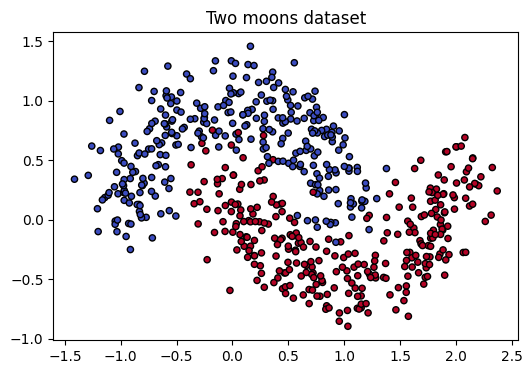

Training points: 450  Test points: 150


In [6]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

torch.manual_seed(0)
X, y = make_moons(n_samples=600, noise=0.2, random_state=0)

# Keep 25% of the points hidden from training, to test the network fairly later
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

# Fancy graphing stuff (look this part up if you want, it's not too important though)
plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k", s=20)
plt.title("Two moons dataset")
plt.show()

print("Training points:", len(X_train), " Test points:", len(X_test))

Convert the data from NumPy arrays into PyTorch tensors:

In [7]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)   # shape (n, 1) which means a grid of [n rows of data] x [1 output value per row of data]
X_test_t  = torch.tensor(X_test,  dtype=torch.float32)
y_test_t  = torch.tensor(y_test,  dtype=torch.float32).unsqueeze(1)

print(X_train_t.shape, y_train_t.shape)

torch.Size([450, 2]) torch.Size([450, 1])


### Build the model

- 2 inputs (the x and y position of a point)
- A hidden layer of 16 neurons with the **ReLU** activation function (ReLU keeps positive numbers and turns negative numbers into 0)
- 1 output: a score where higher means "more likely group 1"

In [8]:
torch.manual_seed(0) # comment out to get random outcomes! but this makes everyone's output the same so we can compare

model = nn.Sequential(
    nn.Linear(2, 16),
    nn.ReLU(),
    nn.Linear(16, 1),
)

print(model)
print("Number of weights and biases:", sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Linear(in_features=2, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
)
Number of weights and biases: 65


### Choose how to measure mistakes and how to fix them

- **Loss function**: a single number for how wrong the model is. Lower is better.
- **Optimizer**: the thing that adjusts the weights to make the loss smaller. The **learning rate** (`lr`) controls how big each adjustment is.

In [9]:
loss_fn = nn.BCEWithLogitsLoss()                         # standard loss for yes/no (two-class) problems
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

DO NOT EXPAND\
Ok, ok, fine... I'll tell you...\
BCEWithLogitsLoss means Binary Cross Entropy With Logits Loss. It uses the formula $$-\frac1N\sum^N_{i=1}{y_i \log(p_i) + (1-y_i) \log(1-p_i)}$$ 
with i meaning the i-th data point (so this is the average loss over all data points)\
with $p_i$ being the probability the model assigns to the true value with a softmax function and\
$y_i$ being the true probability of the true value (which is 1 in this case)\
Are you satisfied now?

### The training loop

Every pass through the loop is one **epoch**:

1. **Forward pass**: run the data through the model to get predictions.
2. **Measure the loss**: how wrong were the predictions?
3. **Backward pass**: `loss.backward()` works out which direction to nudge each weight to reduce the loss. This is backpropagation, and PyTorch does it for us automatically.
4. **Update**: `optimizer.step()` nudges every weight a little in that direction.

Repeat many times, and the model gets better.

In [10]:
losses = []

for epoch in range(500):
    predictions = model(X_train_t)            # 1. forward pass
    loss = loss_fn(predictions, y_train_t)    # 2. how wrong are we?

    optimizer.zero_grad()                     # clear the previous step's nudges
    loss.backward()                           # 3. figure out which way to nudge each weight to decrease loss (better predictions)
    optimizer.step()                          # 4. nudge the weights

    losses.append(loss.item())
    if epoch % 100 == 0:
        print(f"epoch {epoch:3d}   loss {loss.item():.4f}")

print(f"final loss {losses[-1]:.4f}")

epoch   0   loss 0.6805
epoch 100   loss 0.2185
epoch 200   loss 0.1360
epoch 300   loss 0.0826
epoch 400   loss 0.0596
final loss 0.0490


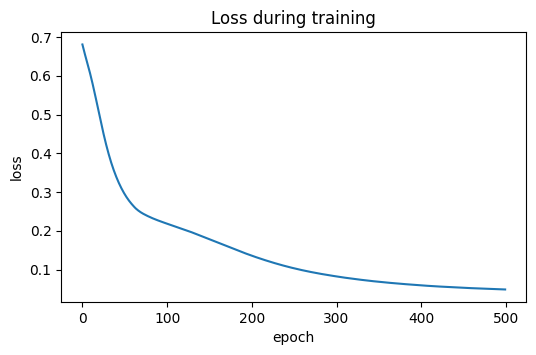

In [11]:
plt.figure(figsize=(6, 3.5))
plt.plot(losses)
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Loss during training")
plt.show()

### How good is it?

We test on the points the model **never saw during training**. That tells us whether it actually learned the pattern instead of memorizing the training points.

In [12]:
def accuracy(model, X_t, y_t):
    with torch.no_grad():
        predicted_class = (model(X_t) > 0).float()   # score above 0 means "group 1"
    return (predicted_class == y_t).float().mean().item()

print(f"Training accuracy: {accuracy(model, X_train_t, y_train_t):.1%}")
print(f"Test accuracy:     {accuracy(model, X_test_t, y_test_t):.1%}")

Training accuracy: 98.4%
Test accuracy:     94.0%


### See what the network learned

The helper below colors every spot on the map by what the model would predict there. You don't need to understand this cell; just run it.

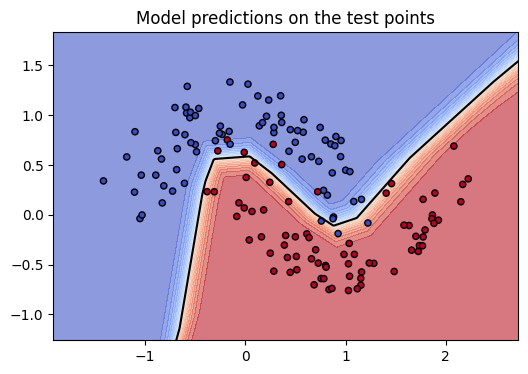

In [13]:
def plot_decision_boundary(model, X, y, title="What the model learned"):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 300),
                         np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 300))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    with torch.no_grad():
        zz = torch.sigmoid(model(grid)).numpy().reshape(xx.shape)
    plt.figure(figsize=(6, 4))
    plt.contourf(xx, yy, zz, levels=20, cmap="coolwarm", alpha=0.6)
    plt.contour(xx, yy, zz, levels=[0.5], colors="k", linewidths=1.5)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k", s=20)
    plt.title(title)
    plt.show()

plot_decision_boundary(model, X_test, y_test, "Model predictions on the test points")

The black line is where the model switches its prediction from one group to the other. A neural network can learn a **curved** boundary like this, which a single straight line can't do.

## Part 4: Experiments

Everything is wrapped in one function below so you can change a setting and retrain quickly. Run this cell once to set it up.

In [14]:
def train(hidden_size=16, activation=nn.ReLU(), lr=0.01, epochs=500, seed=0):
    torch.manual_seed(seed)
    model = nn.Sequential(nn.Linear(2, hidden_size), activation, nn.Linear(hidden_size, 1))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        loss = loss_fn(model(X_train_t), y_train_t)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    print(f"final loss {loss.item():.4f}   test accuracy {accuracy(model, X_test_t, y_test_t):.1%}")
    return model

**Experiment 1: How many hidden neurons?** Try `hidden_size` values like 1, 2, 4, 16, 64. Does more always help?

final loss 0.2564   test accuracy 86.0%


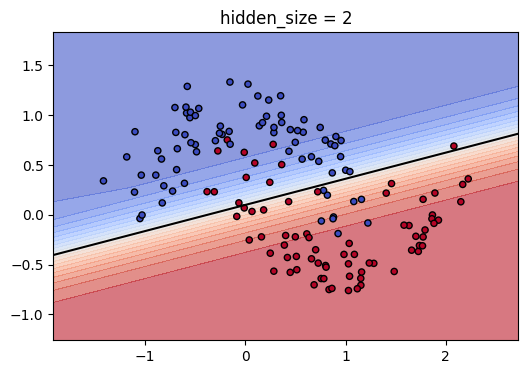

In [15]:
hsize = 2
m = train(hidden_size=hsize)
plot_decision_boundary(m, X_test, y_test, f"hidden_size = {hsize}")

**Experiment 2: Learning rate.** Try `lr` values like 0.0001, 0.01, 1.0. What happens when it's too small? Too big?

final loss 0.6370   test accuracy 81.3%


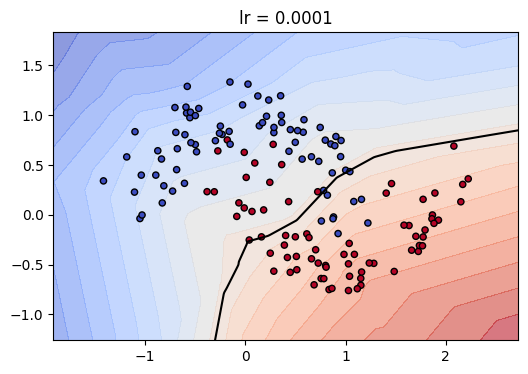

In [16]:
lr = 0.0001
m = train(lr=lr)
plot_decision_boundary(m, X_test, y_test, f"lr = {lr}")

**Experiment 3: Remove the activation function.** `nn.Identity()` means "do nothing": no ReLU, no tanh. What shape is the boundary now, and why?

final loss 0.2547   test accuracy 86.0%


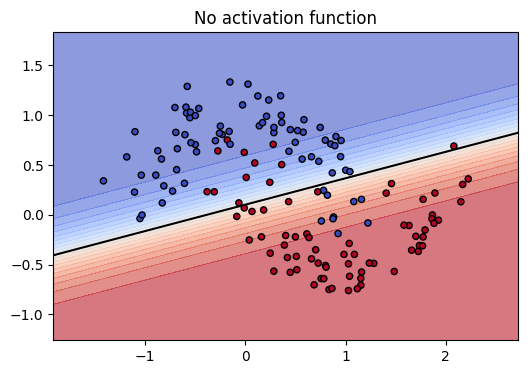

In [17]:
m = train(activation=nn.Identity())
plot_decision_boundary(m, X_test, y_test, "No activation function")

**Experiment 4: Try tanh**, the activation function from the slides, instead of ReLU.

final loss 0.0552   test accuracy 94.0%


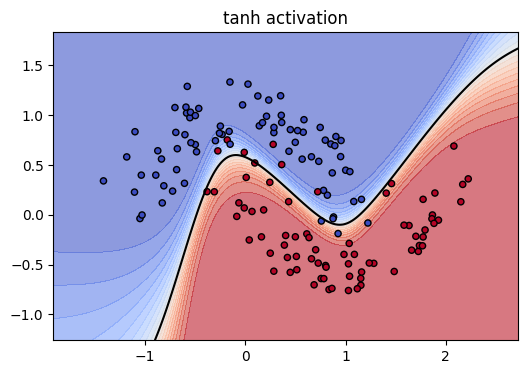

In [18]:
m = train(activation=nn.Tanh())
plot_decision_boundary(m, X_test, y_test, "tanh activation")

### Challenge

Go back to the dataset cell in Part 3 and change `noise=0.2` to `noise=0.4`, then rerun everything. The groups now overlap more. What's the best test accuracy you can get by changing the settings in `train()`?

Bonus: add a second hidden layer by editing the `nn.Sequential(...)` inside `train()`.